# 05 · Treinamento efetivamente executado

A receita local está explícita. Nenhum hiperparâmetro local é atribuído ao paper.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import torch
from IPython.display import display, Markdown, Image, Video
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / 'seminar_5']
            if (p / 'experiments/configs/demo.json').exists())
sys.path.insert(0, str(ROOT / 'experiments/scripts'))
import experiment as exp
torch.set_num_threads(2)
config = json.loads((ROOT / 'experiments/configs/demo.json').read_text())
protocol = json.loads((ROOT / 'experiments/results/protocol.json').read_text())
print('Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.')


Demonstração conceitual MNIST/PCA/MLP. Não é reprodução de FID/CLIP LAION.


In [2]:
print(json.dumps(config, indent=2, ensure_ascii=False))
print('Durações (s):', protocol['durations'])
print('Hardware:', protocol['hardware'], protocol['platform'])
print('Python/bibliotecas:', protocol['python'], protocol['versions'])
print('SHA-256 checkpoints:', protocol['checkpoint_sha256'])

{
  "classification": "Demonstração conceitual do LCD, não reprodução quantitativa de Stable Diffusion",
  "seed": 42,
  "train_per_class": 600,
  "val_per_class": 100,
  "test_per_class": 100,
  "image_size": 14,
  "latent_dim": 32,
  "hidden_dim": 128,
  "timesteps": 1000,
  "beta_start": 0.00085,
  "beta_end": 0.012,
  "teacher_steps": 5000,
  "student_steps": 5000,
  "classifier_steps": 1000,
  "batch_size": 128,
  "teacher_lr": 0.001,
  "student_lr": 0.0002,
  "classifier_lr": 0.001,
  "ema": 0.99,
  "guidance_min": 0.0,
  "guidance_max": 2.0,
  "eval_guidance": 1.0,
  "skip_intervals": [
    1,
    20
  ],
  "inference_steps": [
    1,
    2,
    4,
    8
  ],
  "sample_seeds": [
    101,
    202,
    303
  ],
  "samples_per_class": 30,
  "boundary_time_scale": 10.0,
  "sigma_data": 0.5,
  "threads": 2
}
Durações (s): {'classifier_seconds': 0.4723199239997484, 'teacher_seconds': 4.904439066998748, 'lcm_k1_seconds': 9.386053602000175, 'lcm_k20_seconds': 9.059557160999248}
Hardware

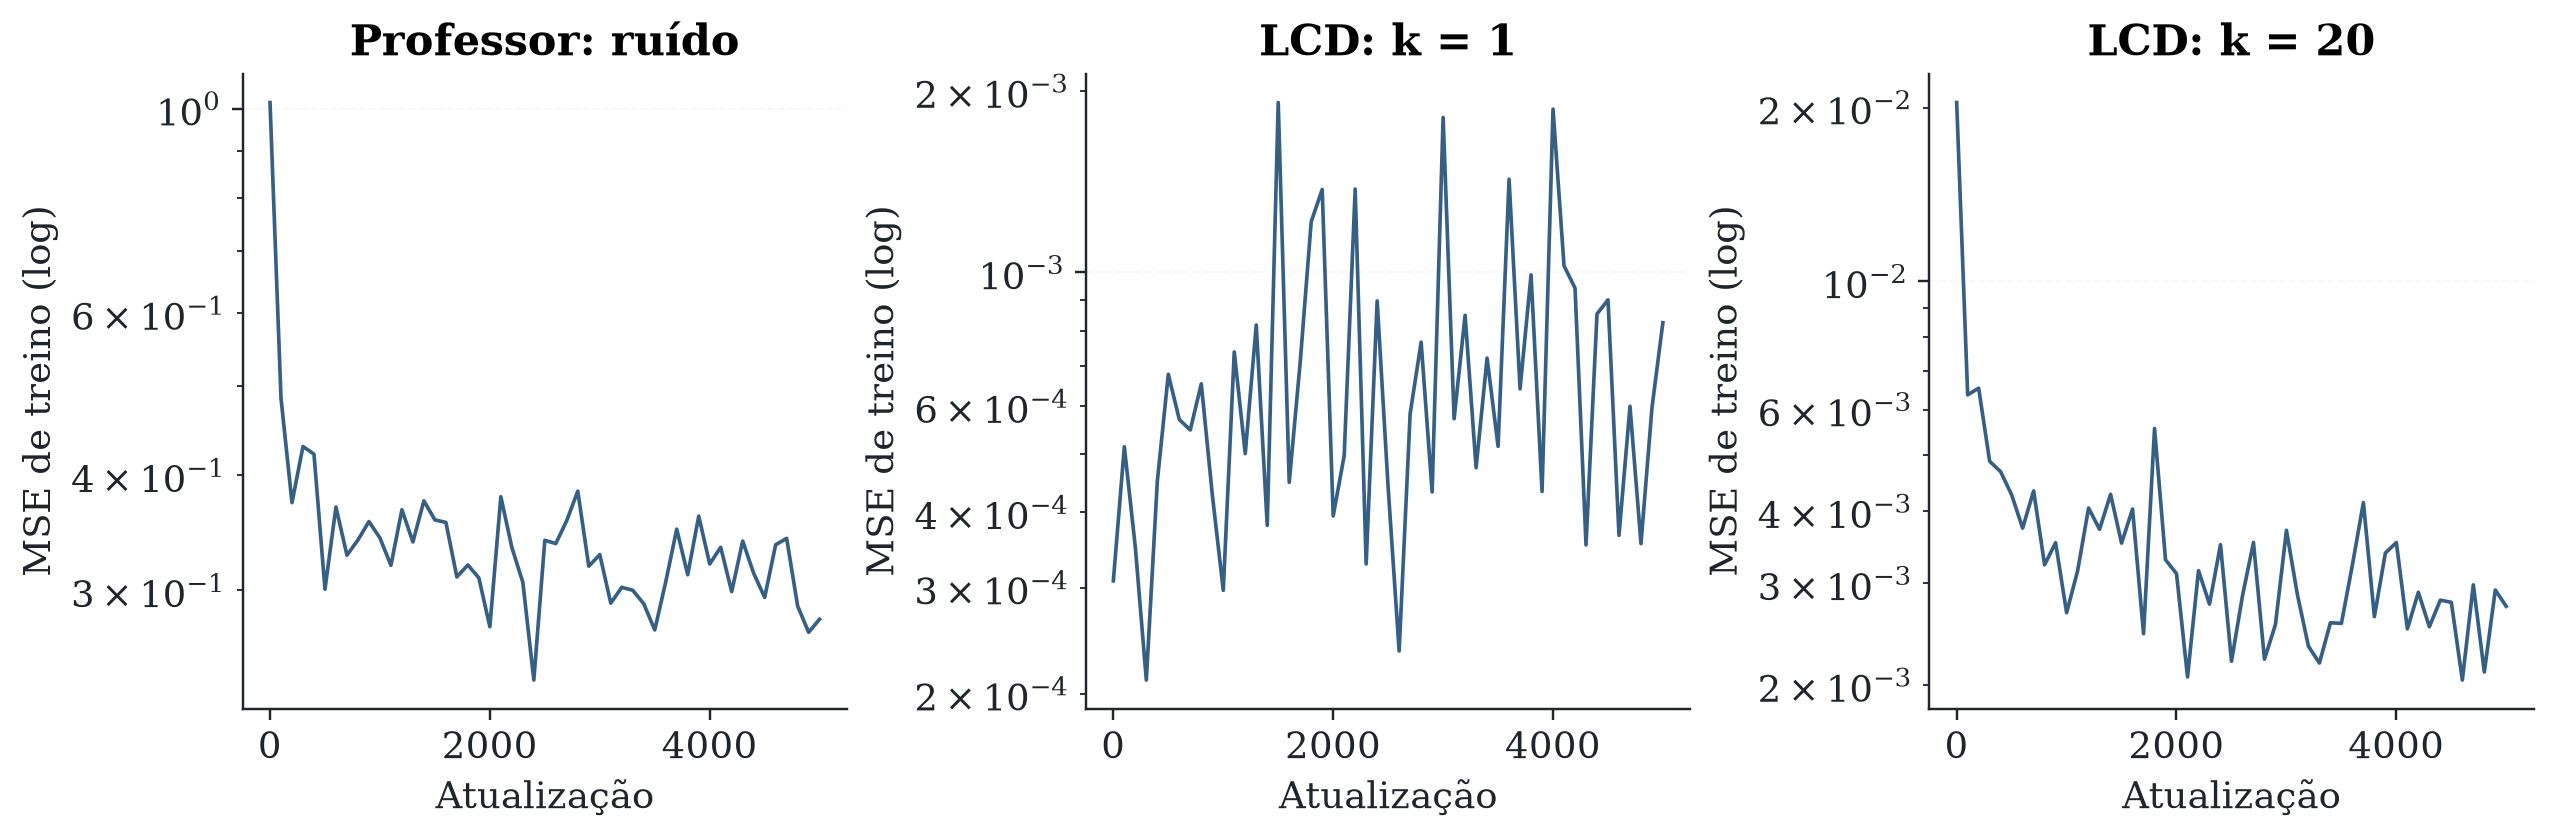

In [3]:
display(Image(filename=str(ROOT / 'assets/figures/training.png')))

As perdas têm escalas diferentes. k=1 pode ter perda menor por comparar estados próximos. A geração é avaliada separadamente. Os modelos foram treinados uma vez por configuração, sem seleção no teste.

In [4]:
RUN_FULL_TRAINING = False
if RUN_FULL_TRAINING:
    exp.train(config)
else:
    print('Treino completo já executado. Para refazer e atualizar checkpoints, mude RUN_FULL_TRAINING para True ou execute python3 seminar_5/run.py experiment.')

Treino completo já executado. Para refazer e atualizar checkpoints, mude RUN_FULL_TRAINING para True ou execute python3 seminar_5/run.py experiment.


Após refazer treino, regenere figuras, animações, slides e notebooks. Não mantenha gráficos ou narrativa numérica de uma execução antiga.